# Detection of errors in a dataset with known identities

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sadda/turtle_re_id/blob/master/examples/error_detection.ipynb)

This notebook shows how to use the `animal_re_id` package to find errors in a dataset where every photo already has an identity. Two typical errors are a turtle stored under two different identities and a photo stored under a wrong identity. Every photo is compared with all photos of the other identities, and a strong match between two different identities points to an error. As in the [discovery notebook](discovery.ipynb), the turtles are first segmented into body parts (head, front flippers, hind flippers), and each body part is matched separately.

The workflow consists of:

1. **Detection** – the TurtleDetector finds the body parts in every photo.
2. **Re-identification** – every body part of every photo is compared with the same body part in the photos of all other identities.
3. **Verification** – the most promising pairs of photos are exported for manual verification in a visual app.
4. **Error detection** – the verified answers are summarised for every pair of identities to decide which identities should be merged and which photos should be moved.

All computed results are stored and reused in the same way as in the introduction notebook.

## 0. Configuration and Data Preparation

When running in Google Colab, we first install the `animal_re_id` package. Then we load all required functions.

In [1]:
import sys

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    %pip install -q "animal-re-id[models] @ git+https://github.com/sadda/turtle_re_id" "numpy<2.5"

In [2]:
import os
import warnings
from pathlib import Path

import pandas as pd
from wildlife_datasets.datasets import Dataset_FolderStructured
from wildlife_tools.similarity import MaskedPairSelector, MetadataIgnoreMask, TopkPairSelector

from animal_re_id.datasets import TurtlesFromMetadata
from animal_re_id.datasets.utils import check_image_ids, show_tree
from animal_re_id.examples import download_example
from animal_re_id.models import EncounterPredictions, Wildfusion_Similarity, get_pipeline_aliked, get_pipeline_miew, merge_data, run_detection_cached, turtle_detector, visualise_matches
from animal_re_id.verification import answers_to_errors, generate_answers_errors

warnings.filterwarnings("ignore", message=".*copying from a non-meta parameter.*")

The notebook expects all photos in the folder `root`. The candidate pairs for verification are saved to `file_name_verification`, and the answers from the verification are loaded from `file_name_answers`. We specify that we run the computation on CPU, not GPU. The option `img_load="bbox"` means that every body part is cropped by its bounding box before matching, and `matching_parts` lists the body parts that are used for re-identification.

In [3]:
root = "data_errors"
file_name_verification = "verification_data.csv"
file_name_answers = "answers.csv"
root_cache = "output/cache_Example_errors"

device = "cpu"
img_load = "bbox"
matching_parts = ["heads", "front flippers", "hind flippers"]

We now download the same 17 photos as in the discovery notebook, but stored with their identities as `<identity>/<date>/<encounter>/<photo>`. Two errors were introduced into the dataset:

- The encounter `2019-09-02/1` of `t023` is stored under the new identity `t999`. One turtle is therefore split into two identities.
- The photo `SyqTAcuxZl.jpeg` of `t243` is stored in the encounter `2021-06-27/1` of `t441`. One photo therefore has a wrong identity.

The true identities are given at the end of the notebook so that the results can be checked. We also show the folder structure.

In [4]:
download_example("data_errors", root, [root])
show_tree(Path(root))

📄 metadata.csv
📄 segmentation.csv
📁 t023
  📁 2019-09-01
    📁 1
      📄 bFDAvrYiWl.JPG
📁 t048
  📁 2016-09-11
    📁 1
      📄 BKSZniWdEy.JPG
      📄 cMFAwnBoCL.JPG
📁 t217
  📁 2018-06-22
    📁 1
      📄 FDtYdNhYIi.JPG
      📄 uuXwVsxzcv.jpg
  📁 2018-08-22
    📁 1
      📄 SRjuDXBzDi.JPG
📁 t243
  📁 2019-09-01
    📁 2
      📄 BOKUrkCMiG.JPG
      📄 EIROuwuCWc.JPG
  📁 2021-06-22
    📁 1
      📄 kURonwyWUl.jpeg
📁 t323
  📁 2019-09-01
    📁 3
      📄 JuzrPoNPdO.JPG
      📄 gSrnbelCRg.JPG
📁 t441
  📁 2019-09-04
    📁 1
      📄 AWmdGjCEnN.JPG
  📁 2021-06-27
    📁 1
      📄 FXclXOIMbN.jpeg
      📄 SyqTAcuxZl.jpeg
      📄 eyoBZoWteN.jpeg
📁 t999
  📁 2019-09-02
    📁 1
      📄 RGgyZSkQxK.JPG
      📄 nRYVdYfqBM.JPG


## 1. Detection

The metadata are created from the folder structure by `Dataset_FolderStructured`. Unlike in the discovery notebook, the identity is known from the folder name. The photos of the same turtle taken on the same day form one **encounter** (`<date>/<folder>`).

The [TurtleDetector](https://huggingface.co/BVRA/TurtleDetector) then detects the turtle body, the head and the four flippers in every photo and stores their bounding boxes, masks, labels and confidence scores. Both tables are saved next to the photos as `metadata.csv` and `segmentation.csv`. Finally, example photos are plotted.

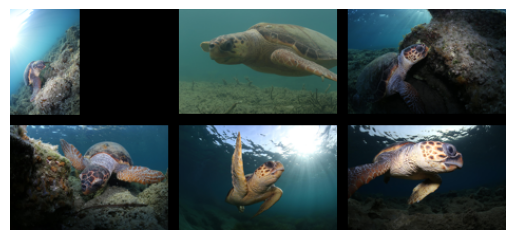

In [5]:
model = turtle_detector()
dataset = Dataset_FolderStructured(root, levels=("identity", "date", "encounter"))
dataset.metadata["encounter_id"] = dataset.metadata["date"] + "/" + dataset.metadata["encounter"]
dataset.metadata.to_csv(f"{root}/metadata.csv", index=False)

run_detection_cached(dataset, model, f"{root}/segmentation.csv")

dataset.plot_grid(idx=range(6), n_rows=2, n_cols=3, rotate=False);

The dataset in `TurtlesFromMetadata` loads `metadata.csv` together with `segmentation.csv`. Every detected body part becomes one row, and detections with low confidence are removed. The identities from the folder structure are kept, so the candidates for every photo are the other identities.

In [6]:
dataset_kwargs = {"img_load": img_load}
query_dataset = TurtlesFromMetadata(root, dataset_kwargs=dataset_kwargs)

The detector labels are grouped into **matching parts**: `heads`, `front flippers` (left and right) and `hind flippers` (left and right). Each grid shows the crops of one matching part.

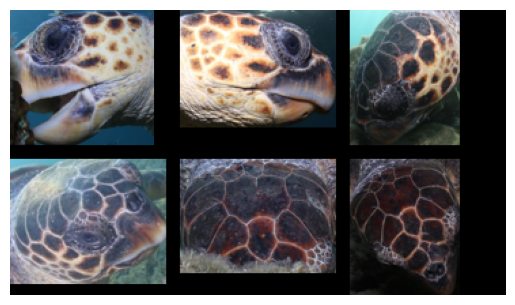

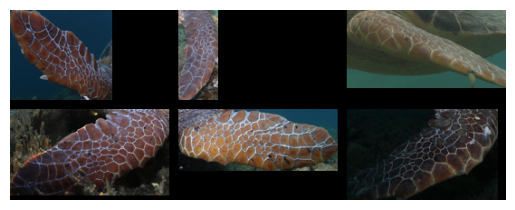

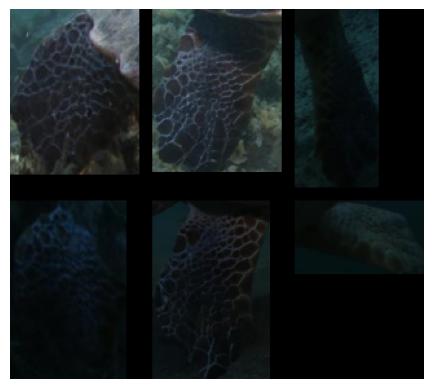

In [7]:
for matching_part in matching_parts:
    wildlife_dataset = query_dataset.for_matching_part(matching_part).wildlife_dataset
    wildlife_dataset.plot_grid(n_rows=2, n_cols=3, rotate=False)

## 2. Re-identification based on individual parts

The matching is the same as in the discovery notebook, with two differences:

- `MaskedPairSelector` ignores the pairs of photos with the same identity. The photos of one identity are expected to match, and only matches between different identities point to an error.
- `encounter_col="path"` makes every photo its own encounter. An error may concern a single photo, so the evidence from the photos of an encounter must not be combined.

`EncounterPredictions.classify` and `merge_data` then create and merge the predictions of all matching parts, where the candidate identities are the other identities.

In [8]:
cache_prefix = f"{root_cache}/{img_load}"
miew = get_pipeline_miew(device=device, cache_prefix=cache_prefix)
aliked = get_pipeline_aliked(device=device, cache_prefix=cache_prefix)
B = 5

pair_selector = MaskedPairSelector(TopkPairSelector(), MetadataIgnoreMask(cols_equal=["identity"]))
wildfusion = Wildfusion_Similarity(miew, aliked, B=B, pair_selector=pair_selector)

predictions = []
for matching_part in matching_parts:
    query = query_dataset.for_matching_part(matching_part).wildlife_dataset
    check_image_ids(query.metadata)

    similarity = wildfusion(query, query)
    prediction = EncounterPredictions.classify(similarity, query, query, matching_part, "miew-aliked", k_max=10, encounter_col="path")
    predictions.append(prediction)

merged = merge_data(predictions)

## 3. Verification

We convert the merged predictions into candidate pairs for verification. Every row is one pair of photos with different identities, including the matching part and the raw number of matched keypoints (`similarity_orig`). `max_per_encounter` limits the number of candidates per photo, and `max_matches` limits the total number of pairs. Since the predictions were made for photos, the encounters of both photos are added back to every pair.

The pairs are saved to `verification_data.csv`, which is the input format of the [Image Comparator app](https://github.com/sadda/image-comparator). There, an annotator decides for every pair whether the two turtles are the same, and the answers are saved to `answers.csv`. Manual verification is optional for this notebook.

In [9]:
verification = merged.extract_highest_predictions(max_matches=10, max_per_encounter=2, sort_by="similarity_orig")
verification = verification.sort_values("similarity_orig", ascending=False, ignore_index=True)
metadata = query_dataset.wildlife_dataset.metadata.set_index("image_id")
verification["encounter1"] = verification["image_id1"].map(metadata["encounter_id"])
verification["encounter2"] = verification["image_id2"].map(metadata["encounter_id"])
verification.to_csv(file_name_verification, index=False)
verification[["identity1", "identity2", "encounter1", "encounter2", "matching_part", "similarity_orig"]]

,identity1,identity2,encounter1,encounter2,matching_part,similarity_orig
0,t999,t023,2019-09-02/1,2019-09-01/1,front flippers,94.0
1,t441,t243,2021-06-27/1,2019-09-01/2,heads,40.0
2,t243,t217,2021-06-22/1,2018-06-22/1,heads,33.0
3,t441,t999,2021-06-27/1,2019-09-02/1,heads,21.0
4,t999,t323,2019-09-02/1,2019-09-01/3,front flippers,18.0
5,t441,t999,2019-09-04/1,2019-09-02/1,heads,18.0
6,t441,t048,2019-09-04/1,2016-09-11/1,heads,17.0
7,t441,t217,2021-06-27/1,2018-06-22/1,heads,17.0
8,t999,t243,2019-09-02/1,2019-09-01/2,front flippers,17.0
9,t441,t243,2021-06-27/1,2021-06-22/1,heads,17.0


For the three pairs with the highest scores, the two crops are matched again and the matched keypoints are connected by lines. Only confident matches are kept, so the number of lines roughly corresponds to the score. For a correct match, many lines connect corresponding scales and run roughly in parallel. These are the same images that the annotator compares in the app.

Loaded LightGlue model


100%|█████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00,  3.04it/s]


Loaded LightGlue model


100%|█████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00, 27.22it/s]


Loaded LightGlue model


100%|█████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00, 15.62it/s]


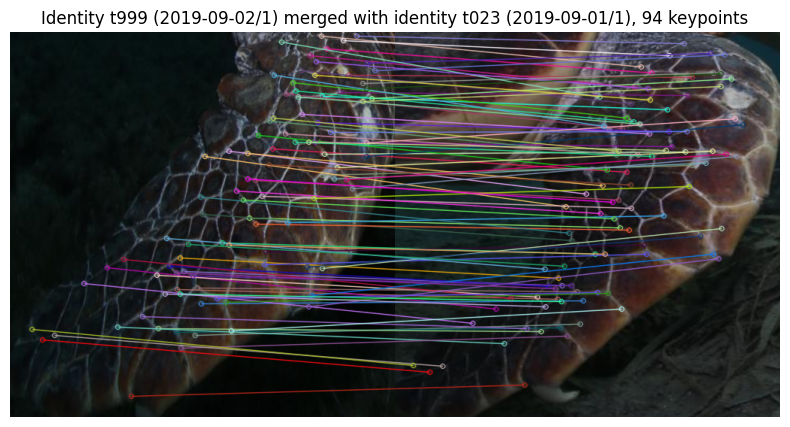

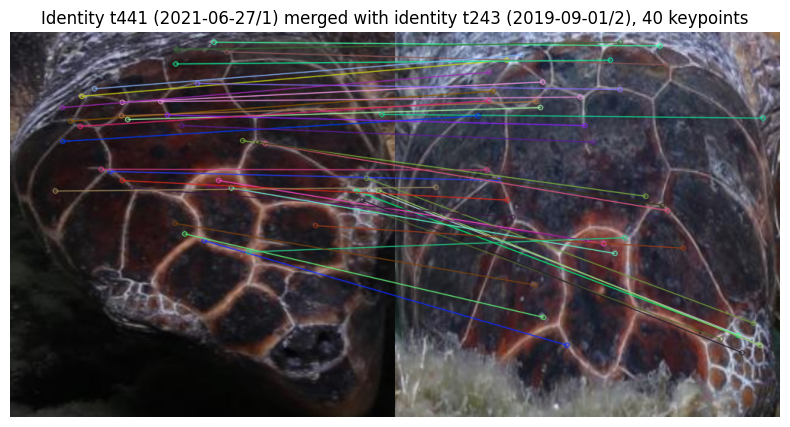

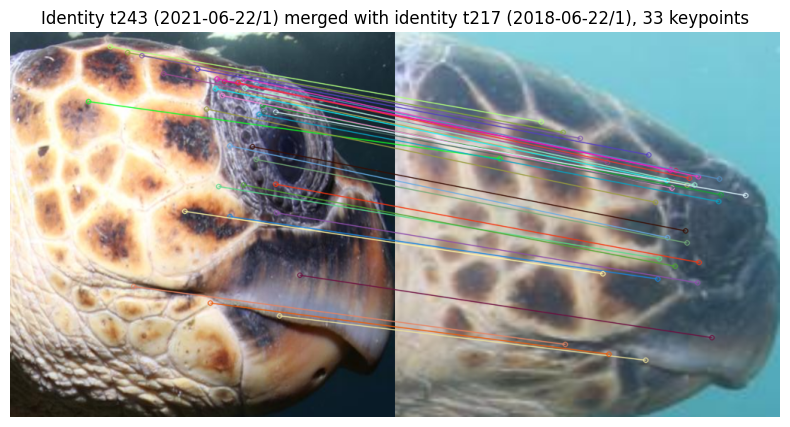

In [10]:
for _, row in verification.iloc[:3].iterrows():
    title = f"Identity {row['identity1']} ({row['encounter1']}) merged with identity {row['identity2']} ({row['encounter2']}), {row['similarity_orig']:.0f} keypoints"
    query = query_dataset.for_matching_part(row["matching_part"]).wildlife_dataset
    database = query_dataset.for_matching_part(row["matching_part"]).wildlife_dataset
    visualise_matches(query, database, row, aliked, "aliked", title=title)

## 4. Error detection

If the verification has been performed manually, the answers are loaded from `file_name_answers`. Otherwise, `generate_answers_errors` simulates an annotator who knows the true identity of every photo and selects either `same` or `different`. The true identities are given by correcting the two errors: `t999` is renamed to `t023`, and the photo `SyqTAcuxZl.jpeg` is assigned to `t243`.

In [11]:
true_identities = {"t999": "t023"}
true_images = {"SyqTAcuxZl.jpeg": "t243"}

true_identity = {}
for image_id, path, identity in zip(metadata.index, metadata["path"], metadata["identity"]):
    file_name = os.path.basename(path)
    true_identity[image_id] = true_images.get(file_name, true_identities.get(identity, identity))

if os.path.exists(file_name_answers):
    answers = pd.read_csv(file_name_answers)
else:
    answers = generate_answers_errors(verification, true_identity)
answers[["identity1", "identity2", "encounter1", "encounter2", "matching_part", "similarity_orig", "answer"]]

,identity1,identity2,encounter1,encounter2,matching_part,similarity_orig,answer
0,t999,t023,2019-09-02/1,2019-09-01/1,front flippers,94.0,same
1,t441,t243,2021-06-27/1,2019-09-01/2,heads,40.0,same
2,t243,t217,2021-06-22/1,2018-06-22/1,heads,33.0,different
3,t441,t999,2021-06-27/1,2019-09-02/1,heads,21.0,different
4,t999,t323,2019-09-02/1,2019-09-01/3,front flippers,18.0,different
5,t441,t999,2019-09-04/1,2019-09-02/1,heads,18.0,different
6,t441,t048,2019-09-04/1,2016-09-11/1,heads,17.0,different
7,t441,t217,2021-06-27/1,2018-06-22/1,heads,17.0,different
8,t999,t243,2019-09-02/1,2019-09-01/2,front flippers,17.0,different
9,t441,t243,2021-06-27/1,2021-06-22/1,heads,17.0,same


Finally, `answers_to_errors` lists the pairs of photos answered `same`. Every row is one pair of photos with different identities, where `identity1` is sorted before `identity2`. The photos of each pair of identities decide the type of the error:

- If photos from several encounters of both identities are matched, the two identities are one turtle and should be merged. This is the case of `t023` and `t999`.
- If only a few photos of one identity are matched, these photos are stored under a wrong identity and should be moved. This is the case of the photo of `t243` stored under `t441`.

In [12]:
answers_to_errors(answers, query_dataset.wildlife_dataset.metadata)

,identity1,identity2,path1,path2
0,t023,t999,t023/2019-09-01/1/bFDAvrYiWl.JPG,t999/2019-09-02/1/nRYVdYfqBM.JPG
1,t243,t441,t243/2019-09-01/2/BOKUrkCMiG.JPG,t441/2021-06-27/1/SyqTAcuxZl.jpeg
2,t243,t441,t243/2021-06-22/1/kURonwyWUl.jpeg,t441/2021-06-27/1/SyqTAcuxZl.jpeg
